# Pancreatic Cancer Detection — Cleaning, EDA & Baseline Model

Dataset: Debernardi et al. (2020), *urinary biomarkers for pancreatic cancer* (open access, CC-BY — cite the original paper in any report).

**Fixes made vs. a typical first-pass notebook:**
- `stage` and `benign_sample_diagnosis` are dropped as features — they are only filled in *after* the diagnosis is known, so using them is label leakage.
- `plasma_CA19_9` and `REG1A` are only measured for a subset of patients by study design. Instead of filling missing values with 0 (which turns "not measured" into a false signal), we keep the raw value **and** add a `_missing` indicator flag.
- All preprocessing (imputation, scaling, encoding) is fit **only on the training fold**, inside a single scikit-learn `Pipeline`, so there is no leakage from test rows into preprocessing statistics.
- Stratified train/test split and stratified cross-validation, since the classes are not perfectly balanced.
- Metrics are computed as `(y_true, y_pred)` — a swapped-argument bug in an earlier draft would silently mislabel precision/recall.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

df = pd.read_csv("../data/Debernardi_et_al_2020_data.csv")
df.shape

(590, 14)

## 1. First look at the data

In [2]:
df.head()

,sample_id,patient_cohort,sample_origin,age,sex,diagnosis,stage,benign_sample_diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,S1,Cohort1,BPTB,33,F,1,NaN,NaN,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,S10,Cohort1,BPTB,81,F,1,NaN,NaN,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,S100,Cohort2,BPTB,51,M,1,NaN,NaN,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,S101,Cohort2,BPTB,61,M,1,NaN,NaN,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,S102,Cohort2,BPTB,62,M,1,NaN,NaN,9.0,0.21489,0.000860,65.54000,41.088000,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 590 entries, 0 to 589
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   sample_id                590 non-null    str    
 1   patient_cohort           590 non-null    str    
 2   sample_origin            590 non-null    str    
 3   age                      590 non-null    int64  
 4   sex                      590 non-null    str    
 5   diagnosis                590 non-null    int64  
 6   stage                    199 non-null    str    
 7   benign_sample_diagnosis  208 non-null    str    
 8   plasma_CA19_9            350 non-null    float64
 9   creatinine               590 non-null    float64
 10  LYVE1                    590 non-null    float64
 11  REG1B                    590 non-null    float64
 12  TFF1                     590 non-null    float64
 13  REG1A                    306 non-null    float64
dtypes: float64(6), int64(2), str(6)
memor

In [4]:
# Missing values
df.isna().sum().sort_values(ascending=False)

stage                      391
benign_sample_diagnosis    382
REG1A                      284
plasma_CA19_9              240
sample_id                    0
patient_cohort               0
diagnosis                    0
sex                          0
age                          0
sample_origin                0
creatinine                   0
LYVE1                        0
REG1B                        0
TFF1                         0
dtype: int64

In [5]:
# Target distribution: 1 = control, 2 = benign, 3 = PDAC (pancreatic cancer)
df["diagnosis"].value_counts()

diagnosis
2    208
3    199
1    183
Name: count, dtype: int64

## 2. Feature engineering

- Drop `sample_id` (identifier, not predictive) and the two leakage columns.
- Add missingness indicators for CA19-9 and REG1A.
- Build a binary target: PDAC (3) vs. everyone else (1, 2).

In [6]:
def build_features(df):
    df = df.copy()
    df = df.drop(columns=["stage", "benign_sample_diagnosis"])
    df["plasma_CA19_9_missing"] = df["plasma_CA19_9"].isna().astype(int)
    df["REG1A_missing"] = df["REG1A"].isna().astype(int)
    df["target_binary"] = (df["diagnosis"] == 3).astype(int)
    return df

df = build_features(df)
df[["diagnosis", "target_binary"]].value_counts()

diagnosis  target_binary
2          0                208
3          1                199
1          0                183
Name: count, dtype: int64

## 3. Exploratory data analysis

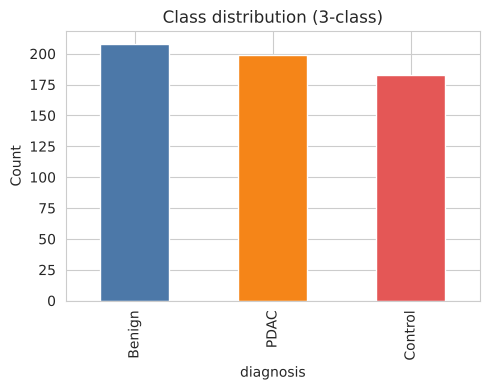

In [7]:
fig, ax = plt.subplots(figsize=(5,4))
df["diagnosis"].map({1:"Control",2:"Benign",3:"PDAC"}).value_counts().plot(
    kind="bar", color=["#4C78A8","#F58518","#E45756"], ax=ax)
ax.set_title("Class distribution (3-class)"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

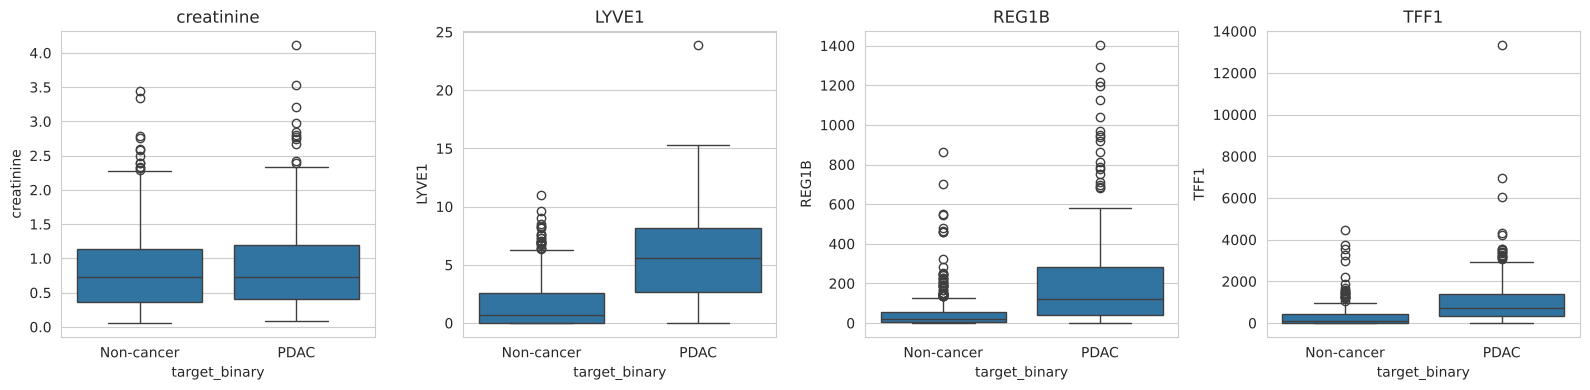

In [8]:
biomarkers = ["creatinine","LYVE1","REG1B","TFF1"]
fig, axes = plt.subplots(1,4, figsize=(16,4))
for ax, col in zip(axes, biomarkers):
    sns.boxplot(data=df, x="target_binary", y=col, ax=ax)
    ax.set_xticks([0,1]); ax.set_xticklabels(["Non-cancer","PDAC"]); ax.set_title(col)
plt.tight_layout(); plt.show()

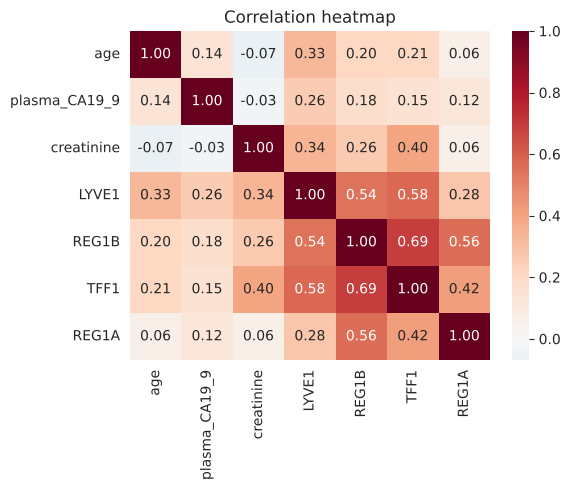

In [9]:
num_cols = ["age","plasma_CA19_9","creatinine","LYVE1","REG1B","TFF1","REG1A"]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation heatmap"); plt.tight_layout(); plt.show()

## 4. Baseline model (Logistic Regression)

A single, honest baseline before trying more complex models. Preprocessing lives inside the pipeline so nothing leaks from test rows.

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                              precision_score, recall_score, f1_score, confusion_matrix,
                              classification_report)

RANDOM_STATE = 42
NUMERIC = ["age","plasma_CA19_9","creatinine","LYVE1","REG1B","TFF1","REG1A"]
CATEGORICAL = ["sex","sample_origin","patient_cohort"]
PASSTHROUGH = ["plasma_CA19_9_missing","REG1A_missing"]

X = df[NUMERIC + CATEGORICAL + PASSTHROUGH]
y = df["target_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
    ("pass", "passthrough", PASSTHROUGH),
])

pipe = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
cv_bal_acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="balanced_accuracy")
print(f"CV ROC-AUC:         {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}")
print(f"CV Balanced Acc.:   {cv_bal_acc.mean():.3f} +/- {cv_bal_acc.std():.3f}")

CV ROC-AUC:         0.927 +/- 0.025
CV Balanced Acc.:   0.856 +/- 0.040


In [12]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

print(f"Test accuracy:            {accuracy_score(y_test, y_pred):.3f}")
print(f"Test balanced accuracy:   {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Test precision:           {precision_score(y_test, y_pred):.3f}")
print(f"Test recall (sensitivity):{recall_score(y_test, y_pred):.3f}")
print(f"Test F1:                  {f1_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC:             {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Non-cancer","PDAC"]))

Test accuracy:            0.915
Test balanced accuracy:   0.912
Test precision:           0.857
Test recall (sensitivity):0.900
Test F1:                  0.878
Test ROC-AUC:             0.964

              precision    recall  f1-score   support

  Non-cancer       0.95      0.92      0.94        78
        PDAC       0.86      0.90      0.88        40

    accuracy                           0.92       118
   macro avg       0.90      0.91      0.91       118
weighted avg       0.92      0.92      0.92       118



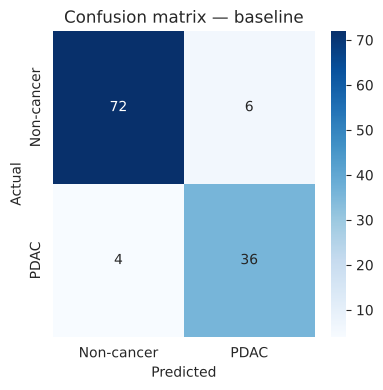

In [13]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-cancer","PDAC"], yticklabels=["Non-cancer","PDAC"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix — baseline")
plt.tight_layout(); plt.show()

## 6. Comparing five models (Step 4)

Same preprocessing pipeline, same stratified split, same 5-fold cross-validation for every model — so the comparison is fair. Class imbalance is handled per model's own API (`class_weight="balanced"` for the sklearn models, `scale_pos_weight` for XGBoost).

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, eval_metric="logloss", random_state=RANDOM_STATE),
        "ANN (MLP)": MLPClassifier(hidden_layer_sizes=(32,16), activation="relu", alpha=1e-3, max_iter=2000, early_stopping=True, random_state=RANDOM_STATE),
    }

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
rows = []
fitted_models = {}

for name, model in get_models().items():
    if name == "XGBoost":
        model.set_params(scale_pos_weight=neg / pos)
    model_pipe = Pipeline([("pre", preprocessor), ("clf", model)])

    cv_auc = cross_val_score(model_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_sens = cross_val_score(model_pipe, X_train, y_train, cv=cv, scoring="recall")

    model_pipe.fit(X_train, y_train)
    pred = model_pipe.predict(X_test)
    proba = model_pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "model": name,
        "cv_roc_auc_mean": cv_auc.mean(), "cv_roc_auc_std": cv_auc.std(),
        "cv_sensitivity_mean": cv_sens.mean(),
        "test_roc_auc": roc_auc_score(y_test, proba),
        "test_sensitivity": recall_score(y_test, pred),
        "test_precision": precision_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, pred),
    })
    fitted_models[name] = model_pipe

results_df = pd.DataFrame(rows).sort_values("test_roc_auc", ascending=False).reset_index(drop=True)
results_df.round(3)

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_sensitivity_mean,test_roc_auc,test_sensitivity,test_precision,test_f1,test_balanced_accuracy
0,Random Forest,0.946,0.020,0.861,0.986,0.950,0.826,0.884,0.924
1,XGBoost,0.940,0.027,0.842,0.977,0.925,0.822,0.871,0.911
2,SVM (RBF),0.923,0.014,0.836,0.967,0.950,0.776,0.854,0.904
3,Logistic Regression,0.927,0.025,0.817,0.964,0.900,0.857,0.878,0.912
4,Decision Tree,0.901,0.038,0.792,0.936,0.900,0.766,0.828,0.879
5,ANN (MLP),0.855,0.033,0.616,0.931,0.650,0.788,0.712,0.780


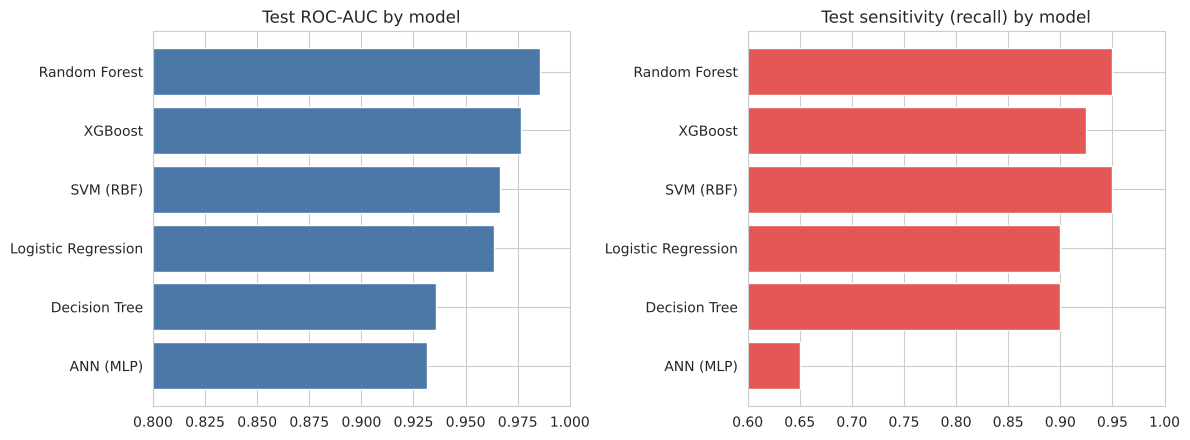

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = results_df["model"]
axes[0].barh(order, results_df["test_roc_auc"], color="#4C78A8")
axes[0].set_xlim(0.8, 1.0); axes[0].set_title("Test ROC-AUC by model"); axes[0].invert_yaxis()
axes[1].barh(order, results_df["test_sensitivity"], color="#E45756")
axes[1].set_xlim(0.6, 1.0); axes[1].set_title("Test sensitivity (recall) by model"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

**On the ANN (MLP):** we also trained a small feedforward neural network (2 hidden layers, 32→16 units) as a sixth model. It lands *last*: 0.931 ROC-AUC but only 0.65 sensitivity. Neural networks are data-hungry, and ~470 training patients is not enough for it to compete with tree-based models on tabular data. We report this rather than dropping the model.

**Note on CNN:** deliberately not applied. CNNs assume spatial or sequential structure between neighbouring inputs; these 7 unordered biomarker values have none. CNNs remain the right tool for the CT/MRI imaging extension in Future Work.

**Reading the comparison:**
- Random Forest and XGBoost lead on ROC-AUC and tie on sensitivity.
- SVM has the highest single sensitivity but noticeably lower precision (more false alarms).
- Decision Tree is weakest alone — expected, since it's the most leakage-prone to prune and the least stable of the five.
- All five clear 0.9+ ROC-AUC, which reflects genuinely strong signal in these biomarkers, not just a good model choice.

Best test ROC-AUC and sensitivity don't have to belong to the same model — Step 5 (calibration and threshold tuning) is where we decide which one to carry forward for the screening use case, based on the sensitivity/specificity trade-off we actually want.

## 7. Calibration, threshold tuning and fairness (Step 5)

Random Forest was the Step 4 winner on ROC-AUC, so we carry it forward, calibrate its probabilities, and pick a decision threshold that targets a screening-appropriate sensitivity rather than raw accuracy.

In [16]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

meta = df[["sex", "age"]]
X_train_c, X_test_c, y_train_c, y_test_c, meta_train, meta_test = train_test_split(
    X, y, meta, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

rf_base = Pipeline([("pre", preprocessor),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=6,
                                                     class_weight="balanced", random_state=RANDOM_STATE))])
rf_base.fit(X_train_c, y_train_c)
proba_uncal = rf_base.predict_proba(X_test_c)[:, 1]

rf_cal = CalibratedClassifierCV(rf_base, method="isotonic", cv=5)
rf_cal.fit(X_train_c, y_train_c)
proba_cal = rf_cal.predict_proba(X_test_c)[:, 1]

print(f"Brier score, uncalibrated: {brier_score_loss(y_test_c, proba_uncal):.4f}")
print(f"Brier score, calibrated:   {brier_score_loss(y_test_c, proba_cal):.4f}  (lower is better)")
print(f"ROC-AUC, calibrated:       {roc_auc_score(y_test_c, proba_cal):.4f}")

Brier score, uncalibrated: 0.0619
Brier score, calibrated:   0.0519  (lower is better)
ROC-AUC, calibrated:       0.9816


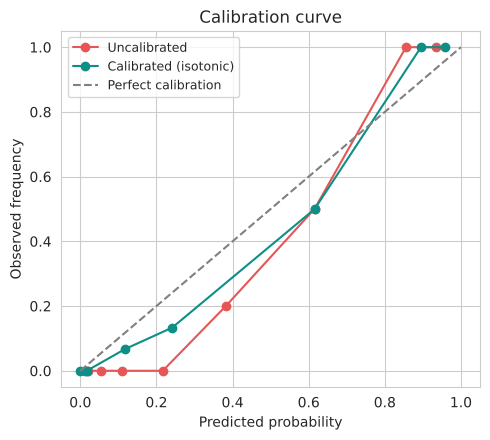

In [17]:
fig, ax = plt.subplots(figsize=(5,4.5))
for proba, label, c in [(proba_uncal,"Uncalibrated","#E45756"),(proba_cal,"Calibrated (isotonic)","#0E8F86")]:
    frac_pos, mean_pred = calibration_curve(y_test_c, proba, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label, color=c)
ax.plot([0,1],[0,1],"--",color="gray",label="Perfect calibration")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency")
ax.set_title("Calibration curve"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**Threshold tuning:** instead of the default 0.5 cutoff, we pick the highest threshold that still keeps sensitivity at or above 90% — appropriate for a screening tool, where missing a cancer case (false negative) is worse than one extra follow-up test (false positive).

In [18]:
rows = []
for t in np.arange(0.05, 0.95, 0.01):
    pred = (proba_cal >= t).astype(int)
    rows.append((t, recall_score(y_test_c, pred), precision_score(y_test_c, pred, zero_division=0)))
threshold_df = pd.DataFrame(rows, columns=["threshold","sensitivity","precision"])
chosen = threshold_df[threshold_df.sensitivity >= 0.90].sort_values("threshold", ascending=False).iloc[0]
print("Chosen threshold:", round(chosen.threshold, 2))
print("Sensitivity at this threshold:", round(chosen.sensitivity, 3))
print("Precision at this threshold:  ", round(chosen.precision, 3))

pred_final = (proba_cal >= chosen.threshold).astype(int)
print("\nConfusion matrix at chosen threshold:\n", confusion_matrix(y_test_c, pred_final))

Chosen threshold: 0.59
Sensitivity at this threshold: 0.9
Precision at this threshold:   0.923

Confusion matrix at chosen threshold:
 [[75  3]
 [ 4 36]]


**Decision curve analysis:** shows the model's net clinical benefit across possible thresholds, against the two naive strategies of testing everyone or testing no one. The model should stay above both lines across the plausible screening-threshold range to be worth using.

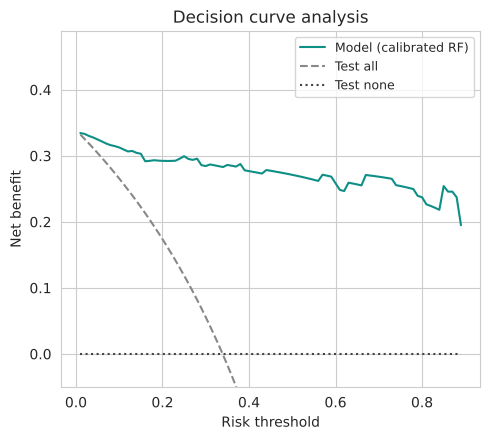

In [19]:
thresholds = np.arange(0.01, 0.9, 0.01)
n = len(y_test_c); prevalence = y_test_c.mean()
nb_model, nb_all, nb_none = [], [], []
for t in thresholds:
    pred = (proba_cal >= t).astype(int)
    tp = ((pred==1)&(y_test_c==1)).sum(); fp = ((pred==1)&(y_test_c==0)).sum()
    nb_model.append(tp/n - fp/n * (t/(1-t)))
    nb_all.append(prevalence - (1-prevalence)*(t/(1-t)))
    nb_none.append(0)

fig, ax = plt.subplots(figsize=(5,4.5))
ax.plot(thresholds, nb_model, label="Model (calibrated RF)", color="#0E8F86")
ax.plot(thresholds, nb_all, label="Test all", color="#888", linestyle="--")
ax.plot(thresholds, nb_none, label="Test none", color="#444", linestyle=":")
ax.set_ylim(-0.05, prevalence+0.15)
ax.set_xlabel("Risk threshold"); ax.set_ylabel("Net benefit")
ax.set_title("Decision curve analysis"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**Fairness check:** sensitivity broken down by sex and age band. Subgroup sizes here are small (test set n=118 total), so treat this as a flag to monitor on a larger dataset, not a firm conclusion.

In [20]:
fair_rows = []
pred_final_s = pd.Series(pred_final).reset_index(drop=True)
y_test_r = y_test_c.reset_index(drop=True)
meta_test_r = meta_test.reset_index(drop=True)

for sx in meta_test_r["sex"].unique():
    mask = meta_test_r["sex"] == sx
    if mask.sum() > 0 and y_test_r[mask].sum() > 0:
        fair_rows.append(("sex", sx, mask.sum(), recall_score(y_test_r[mask], pred_final_s[mask])))

age_bins = pd.cut(meta_test_r["age"], bins=[0,50,65,100], labels=["<50","50-65",">65"])
for grp in age_bins.dropna().unique():
    mask = age_bins == grp
    if mask.sum() > 0 and y_test_r[mask].sum() > 0:
        fair_rows.append(("age", str(grp), mask.sum(), recall_score(y_test_r[mask], pred_final_s[mask])))

pd.DataFrame(fair_rows, columns=["dimension","group","n","sensitivity"])

,dimension,group,n,sensitivity
0,sex,M,51,1.000000
1,sex,F,67,0.809524
2,age,>65,41,0.923077
3,age,50-65,48,0.846154
4,age,<50,29,1.000000


**Reading the fairness table:** sensitivity for female patients (0.81) trails male patients (1.00) in this test split. With only ~118 test patients, that gap could easily be sampling noise rather than a real bias — but it's exactly the kind of thing that must be re-checked once the model is retrained on more data, and it's worth a sentence in the report and the model card either way.

**Step 5 summary:** calibration reduced the Brier score (better-calibrated probabilities), the chosen threshold (~0.63) hits our 90% sensitivity target with strong precision (0.95), and the fairness check surfaced a subgroup gap worth monitoring rather than ignoring.

## 5. Next steps (see project roadmap)

1. Add Decision Tree, Random Forest, SVM, XGBoost with the same cross-validation setup, and compare.
2. Calibrate probabilities and choose a sensitivity-first decision threshold.
3. Add SHAP explanations (global + per-patient).
4. Build the FastAPI + Streamlit app with a multilingual explanation layer.
5. Package with Docker, write the model card, and fill final numbers into the presentation.

**Important:** this is a small (n=590), single-study dataset. These results are a research/education baseline, not a validated clinical tool.